# TF motif activity

`epi.tl.tf_activity` is Epione's default **per-cell TF activity**: for every
cell and motif, how much more or less accessible the motif's peaks are than
peaks with the same sequence bias in the same cell. It needs the peak × motif
matrix and nothing else; no background peaks are sampled.

| Step | Function | Produces |
|------|----------|----------|
| 1 | `epi.tl.add_motif_matrix` (or `epi.tl.add_motif_occupancy`) | `varm['motif']`: peak × motif matches |
| 2 | `epi.tl.tf_activity` | `obsm['tf_activity']`: cell × motif activity (shrunken log fold change) |

chromVAR's deviation Z-scores are still available through the chromVAR port
(`epi.tl.add_background_peaks` + `epi.tl.compute_deviations`; see the
[chromVAR tutorial](t_chromvar)) for results that must match chromVAR or ArchR.

## Part 1 · What `tf_activity` computes

For cell $c$, peak $i$ and motif $m$ the counts are modelled as

$$y_{ic} \sim \mathrm{Poisson}(\mu_{ic}), \qquad
\log \mu_{ic} = \log n_c + \log \pi_i + f_c(b_i) + \gamma_{cm}\,\beta_{im}\,w_{im}.$$

* $\pi_i$ is the peak's share of all reads, the offset chromVAR's expectation
  uses too.
* $b_i$ is the peak's **bias stratum**, one cell of a 30 × 30 quantile grid
  over GC content and log mean accessibility. $f_c(b)$ is a free per-cell rate
  for each stratum, so any cell-specific GC or accessibility bias is absorbed.
  chromVAR handles this bias by sampling matched background peaks.
* $w_{im}$ is the motif match and $\gamma_{cm}$ is the **TF activity**: the log
  fold change of the motif's peaks relative to bias-matched peaks in the same
  cell.

Conditioning on the cell's read count in each stratum removes $f_c$ exactly,
which leaves a multinomial score test with closed-form statistics:

$$U_{cm} = \sum_i w_{im} y_{ic} - \sum_b Y_{cb}\, q^{(1)}_{bm}, \qquad
I_{cm} = \sum_b Y_{cb}\bigl(q^{(2)}_{bm} - (q^{(1)}_{bm})^2\bigr), \qquad
\hat\gamma_{cm} = U_{cm}/I_{cm}.$$

Here $q^{(k)}_{bm}$ is the $\pi$-weighted mean of $w^k$ over the stratum's
peaks. Three further steps follow:

1. **Peak sensitivities.** $\beta_{im}$ measures how strongly each motif peak
   follows the motif's activity across cells. It is estimated by a
   leave-one-out Poisson slope within `groupby` groups, shrunk to the motif's
   mean (James-Stein), and the cells are then re-scored with $w\beta$.
2. **Quasi-Poisson dispersion.** The null's dispersion (about 2, because every
   fragment gives two Tn5 insertions) scales the standard errors.
3. **Adaptive shrinkage.** For each motif, a unimodal prior on $\gamma$ is
   fitted over all cells (Stephens 2017). The output is the posterior mean, so
   shallow cells move towards 0 in proportion to their noise.

All of this reduces to sparse products over the count matrix. On 100k cells it
ran slightly faster than background-peak selection plus `compute_deviations`
(527 vs 574 s) and used about a ninth of the memory (32 vs 284 GB). On small
panels the two take about the same time.

In [1]:
import pathlib, time

import numpy as np
import pandas as pd
import anndata as ad
import anndataoom as oom
import scanpy as sc
import epione as epi

import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse, stats

epi.pl.plot_set()

WORK = pathlib.Path.cwd() / 'data_chromvar'          # shared with the chromVAR tutorial
WORK.mkdir(parents=True, exist_ok=True)
MOTIF_DB = 'motif_db_hg38_jaspar2020_5e5'             # epi.tl.build_motif_database output (hg38, JASPAR2020)

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Part 2 · Data

This tutorial uses the snapATAC2 pbmc5k data and the same 50,000 selected
5 kb tiles as the chromVAR tutorial. The tile matrix is cached in
`data_chromvar/`.

In [2]:
%%time
h5 = WORK / 'pbmc5k.h5ad'
if h5.exists() and h5.stat().st_size > 100_000:
    data = oom.read(str(h5), backed='r+')
else:
    frag = epi.utils.register_datasets().fetch('atac_pbmc_5k.tsv.gz')
    data = epi.pp.import_fragments(str(frag), chrom_sizes=epi.utils.genome.hg38,
                                   file=str(h5), sorted_by_barcode=False)
    epi.pp.tsse(data, epi.utils.get_gene_annotation(epi.utils.genome.hg38))
    data = epi.pp.filter_cells(data, min_counts=1000, max_counts=100000, min_tsse=5)
    epi.pp.add_tile_matrix(data, bin_size=5000)
    epi.pp.select_features(data, n_features=50000)

parts = [ch for _, _, ch in data.X.chunked()]
X = sparse.vstack(parts).tocsr() if sparse.issparse(parts[0]) else sparse.csr_matrix(np.vstack(parts))
obs = pd.DataFrame(data.obs).copy(); obs.index = list(data.obs_names)
var = pd.DataFrame(data.var).copy(); var.index = list(data.var_names)
adata = ad.AnnData(X=X, obs=obs, var=var)
adata = adata[:, adata.var['selected'].astype(bool).values].copy()
print(f'{adata.n_obs:,} cells x {adata.n_vars:,} tiles')

5,166 cells x 50,000 tiles
CPU times: user 3.21 s, sys: 2.95 s, total: 6.15 s
Wall time: 6.42 s


In [3]:
%%time
epi.tl.birmt(adata)                                   # default cell embedding -> obsm['X_birmt']
sc.pp.neighbors(adata, use_rep='X_birmt', n_neighbors=30)
sc.tl.leiden(adata, resolution=0.5, flavor='igraph', directed=False, n_iterations=2,
             random_state=0, key_added='leiden')
sc.tl.umap(adata, random_state=0)
print(adata.obs['leiden'].nunique(), 'Leiden clusters')

  └─ [birmt2] 5,166 cells x 50,000 peaks (min_cells=18); shrinkage=score tiles=[] seq_lambda=0.0


  └─ [birmt2] level-0 timings (s) transpose/sinkhorn/subsample/gram/eig/-/krylov: 0.6 0.5 0.0 2.3 0.6 0.0 2.9
  └─ [birmt2] level peaks: rank=72 alpha=0.8236 beta=0 ks=0.05209 n_features=50000 (8.4s)
computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:08)


running Leiden clustering


    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)


12 Leiden clusters
CPU times: user 40.9 s, sys: 1.05 s, total: 42 s
Wall time: 27.9 s


## Part 3 · Motif matrix and TF activity

`add_motif_matrix` looks the tiles up in the pre-scanned motif database
(JASPAR2020 CORE vertebrates, MOODS p < 5e-5). Without a database, pass
`genome_fasta=` to scan directly; `add_motif_occupancy` does the same scan and
also stores thermodynamic occupancy weights.

`tf_activity` needs the GC content of each peak. It takes it from
`var['gc_bias']`, from the sequences cached by a direct motif scan, or from
`genome_fasta=`. A database lookup reads no sequences, so here the genome is
passed.

`groupby` sets the groups within which peak sensitivities are learnt. Use
the sample, batch or cell-type key, so that differences between cell types do
not decide which peaks count. Here that key is the Leiden clusters.

In [4]:
%%time
epi.tl.add_motif_matrix(adata, motif_database=MOTIF_DB)
t0 = time.perf_counter()
epi.tl.tf_activity(adata, groupby='leiden', genome_fasta=str(epi.utils.genome.hg38.fasta))
t_tfa = time.perf_counter() - t0
A = adata.obsm['tf_activity']
names = np.asarray(adata.uns['tf_activity_names'])
print(f'activity: {A.shape}, {t_tfa:.1f} s')
print({k: v for k, v in adata.uns['tf_activity_params'].items()})

  └─ [motif_matrix] querying database motif_db_hg38_jaspar2020_5e5


  └─ [motif_db] queried 50,000 peaks × 746 motifs → 15,776,240 hits


  └─ [tf_activity] 5,166 cells x 50,000 peaks x 746 motifs; 900 bias strata


  └─ [tf_activity] first-pass scores 3.7s


  └─ [tf_activity] quasi-Poisson dispersion 1.072


...

  └─ [tf_activity] re-scored 16.9s


  └─ [tf_activity] adaptive shrinkage (EM over cells, per motif)


  └─ [tf_activity] ash done 40.4s


  └─ [tf_activity] done. obsm['tf_activity'] = (5166, 746) (post_mean)


activity: (5166, 746), 46.3 s
{'motif_key': 'motif', 'weights_key': None, 'gc_key': 'gc_bias', 'covariates': [], 'n_bins': [30, 30], 'null': 'theoretical', 'peak_sensitivity': 'eb', 'groupby': 'leiden', 'dispersion': 'quasi', 'shrinkage': 'ash', 'score': 'post_mean', 'layer': None, 'n_strata': 900}
CPU times: user 2min 34s, sys: 12.3 s, total: 2min 46s
Wall time: 57.7 s


Outputs:

* `obsm['tf_activity']`: the default score, the posterior-mean log fold change
  (0 means no difference from bias-matched peaks).
* `obsm['tf_activity_z']`: the score-test z, calibrated by the dispersion.
* `obsm['tf_activity_lfc']`: the one-step log fold change before shrinkage.
* `obsm['tf_activity_post_mean']` and `obsm['tf_activity_post_sd']`: the
  posterior mean and posterior standard deviation.
* `uns['tf_activity_names']` and `uns['tf_activity_params']`: motif names and
  the parameters used.

## Part 4 · Plots

`epi.tl.var_deviations`, `epi.tl.positive_tf_regulators`, `epi.pl.var_dev`
and the marker functions read `obsm['tf_activity']` by default.

   var_deviations: top = MA1513.1_KLF15, MA0081.2_SPIB, MA1650.1_ZBTB14, MA0837.1_CEBPE, MA0466.2_CEBPB


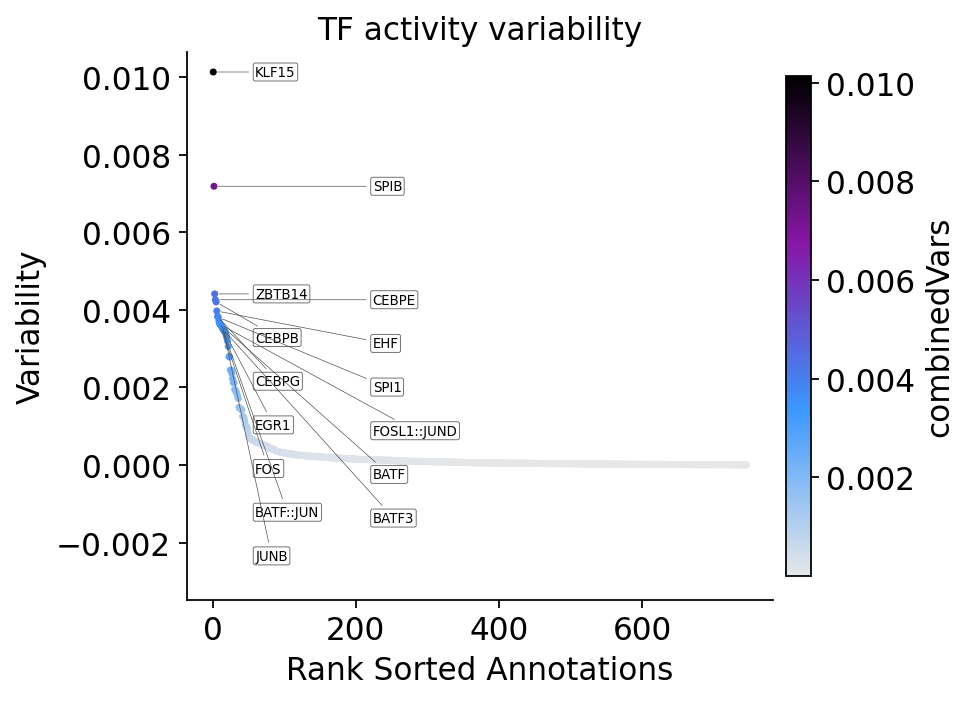

,TF,combinedVars,rank
0,KLF15,0.010133,1
1,SPIB,0.007187,2
2,ZBTB14,0.004411,3
3,CEBPE,0.004261,4
4,CEBPB,0.004205,5
5,EHF,0.003970,6
6,CEBPG,0.003827,7
7,SPI1,0.003809,8
8,EGR1,0.003705,9
9,FOSL1::JUND,0.003632,10


In [5]:
def tf_name(n):
    s = str(n)
    return s.split('_', 1)[-1] if '_' in s else s

var_df = epi.tl.var_deviations(adata, sample_key=None)        # default key: obsm['tf_activity']
fig, ax = epi.pl.var_dev(var_df.assign(name=var_df['name'].map(tf_name)), n=15, figsize=(5, 4.5), show=False)
ax.set_title('TF activity variability')
display(fig); plt.close(fig)
var_df.head(10).assign(TF=lambda d: d['name'].map(tf_name))[['TF', 'combinedVars', 'rank']]

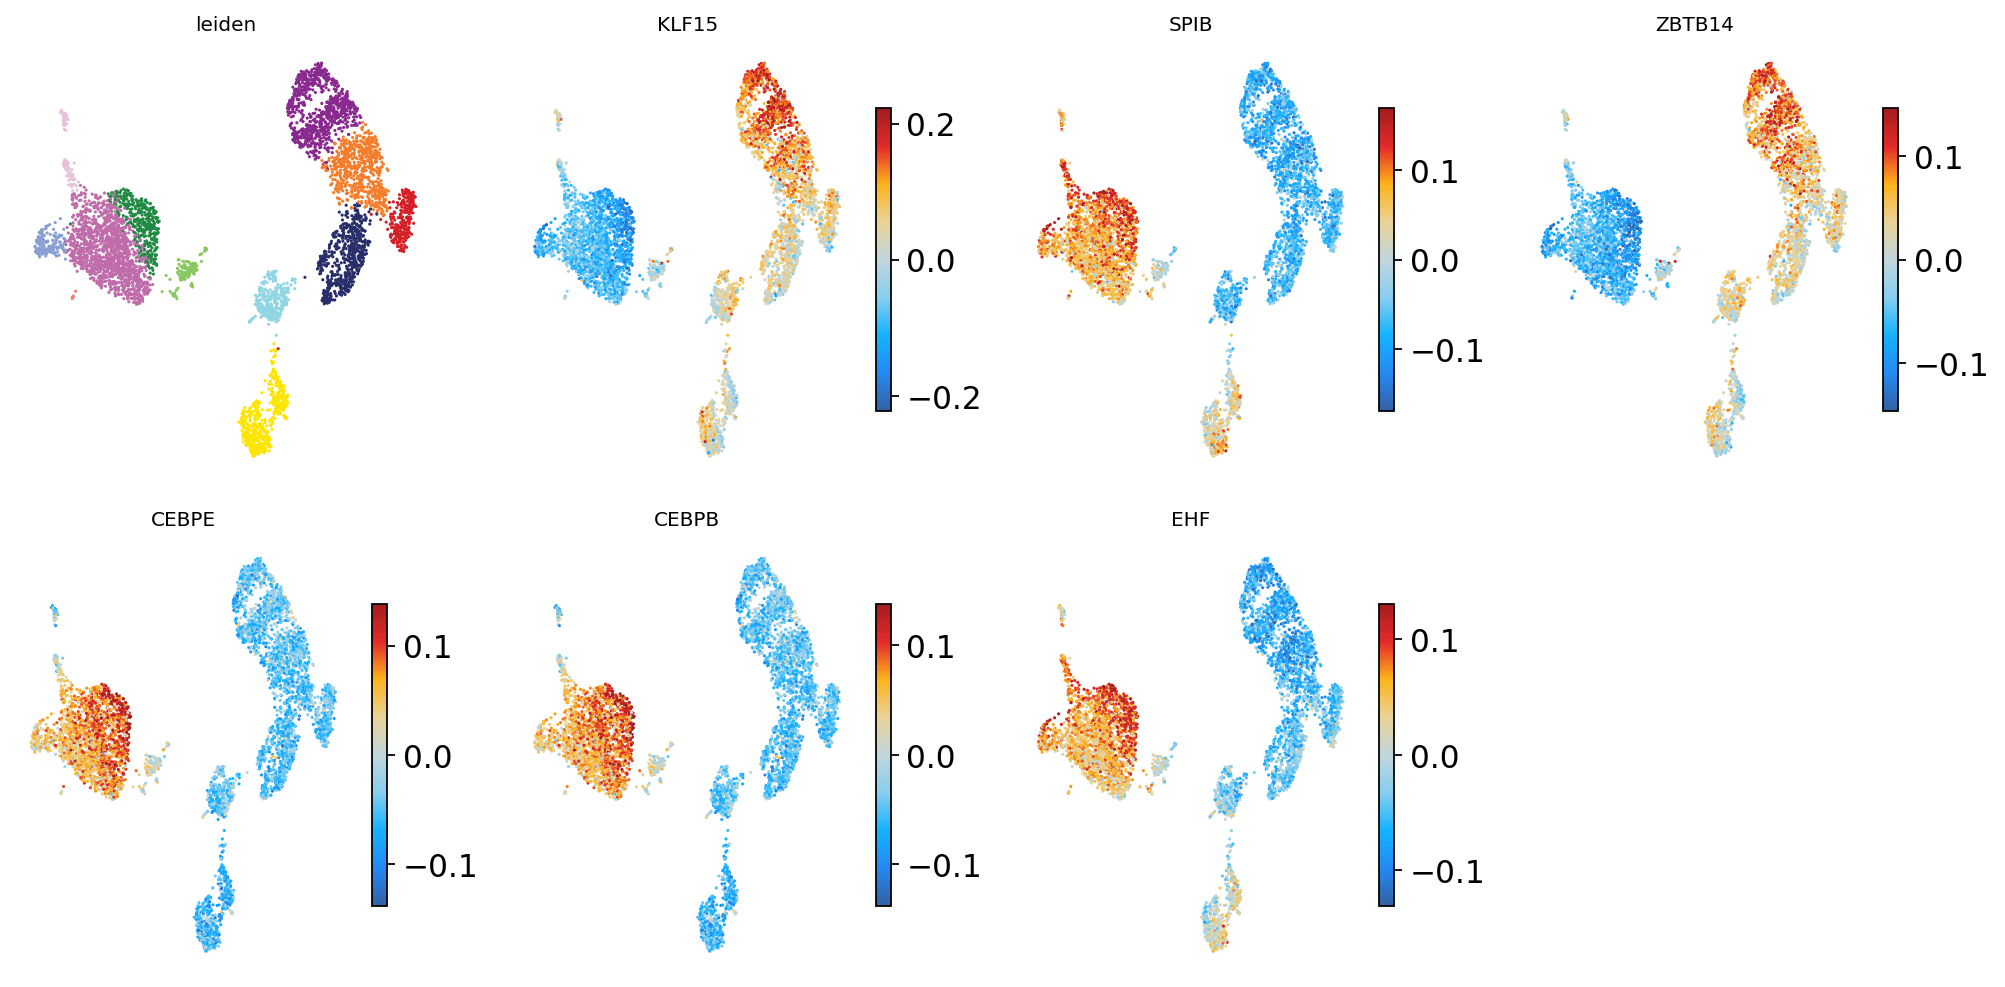

In [6]:
from epione.pl._peak2gene import ARCHR_STALLION
ARCHR_SOLAR = mpl.colors.LinearSegmentedColormap.from_list(
    'archr_solar', ['#3361A5', '#248AF3', '#14B3FF', '#88CEEF', '#C1D5DC',
                    '#EAD397', '#FDB31A', '#E42A2A', '#A31D1D'])
name_to_idx = {n: i for i, n in enumerate(names)}
rank = np.array([name_to_idx[n] for n in var_df['name']])
umap = adata.obsm['X_umap']
top = [names[rank[i]] for i in range(6)]
panels = ['leiden'] + top
fig, axes = plt.subplots(2, 4, figsize=(12.8, 6.4)); axes = axes.ravel()
for ax, col in zip(axes, panels):
    if col == 'leiden':
        cats = adata.obs['leiden'].astype('category').cat.categories
        pal = {c: ARCHR_STALLION[k % len(ARCHR_STALLION)] for k, c in enumerate(cats)}
        ax.scatter(umap[:, 0], umap[:, 1], c=adata.obs['leiden'].map(pal).values, s=2, linewidths=0)
        ax.set_title('leiden', fontsize=9)
    else:
        v = A[:, name_to_idx[col]]
        lim = np.nanpercentile(np.abs(v), 99)
        s_ = ax.scatter(umap[:, 0], umap[:, 1], c=v, s=2, linewidths=0, cmap=ARCHR_SOLAR, vmin=-lim, vmax=lim)
        ax.set_title(tf_name(col), fontsize=9); plt.colorbar(s_, ax=ax, shrink=0.7)
    ax.set_xticks([]); ax.set_yticks([]); ax.spines[:].set_visible(False)
for ax in axes[len(panels):]:
    ax.axis('off')
plt.tight_layout(); display(fig); plt.close(fig)

activity SD 0.017; MeanDiff cut-off 0.008


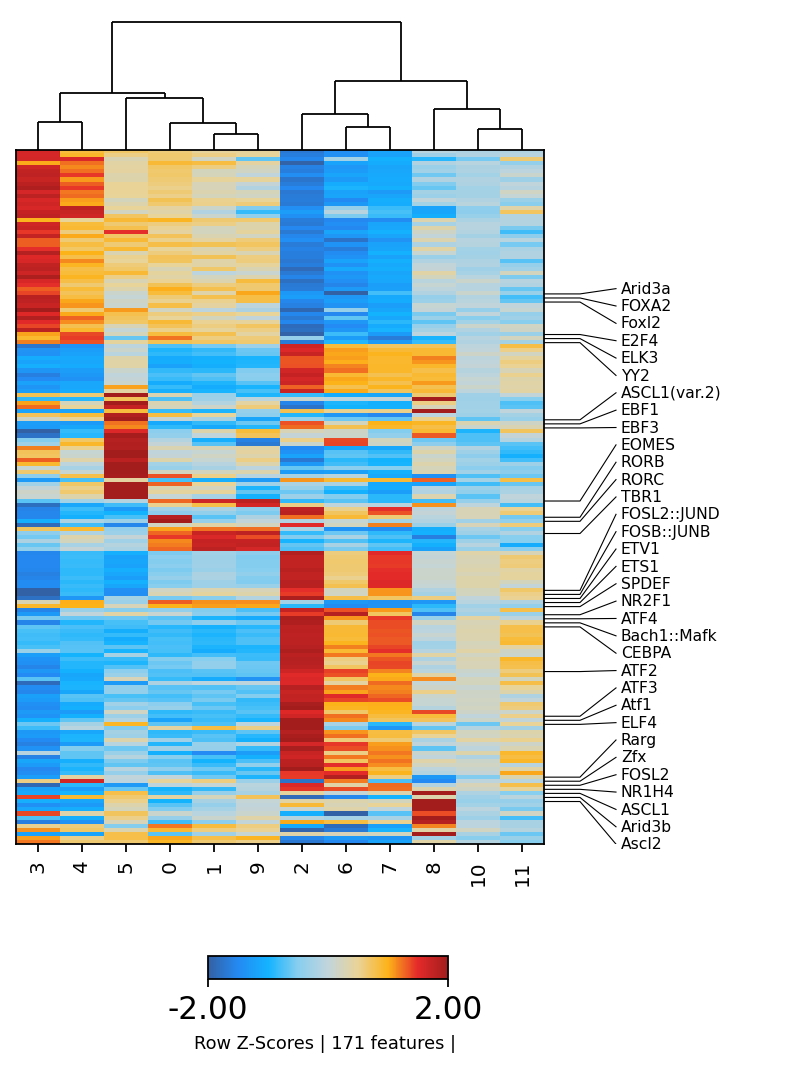

171 marker motifs across 12 clusters
CPU times: user 820 ms, sys: 40 ms, total: 860 ms
Wall time: 863 ms


In [7]:
%%time
motif_ad = ad.AnnData(X=np.asarray(A, dtype=np.float32), obs=adata.obs[['leiden', 'n_fragment', 'tsse']].copy())
motif_ad.var_names = [tf_name(n) for n in names]
motif_ad.var_names_make_unique()
with np.errstate(invalid='ignore', divide='ignore'):
    markers = epi.tl.find_marker_features(motif_ad, group_by='leiden', bias_vars=['tsse', 'n_fragment'],
                                          inplace=False, verbose=False)
wide = lambda col: markers.pivot(index='feature', columns='group', values=col)
assays = {'Mean': wide('mean_fg'), 'MeanDiff': wide('mean_fg') - wide('mean_bg'), 'FDR': wide('fdr')}
thr = 0.5 * float(np.nanstd(A))          # half an activity SD, the analogue of chromVAR's 0.5 Z
print(f'activity SD {np.nanstd(A):.3f}; MeanDiff cut-off {thr:.3f}')
fig, res = epi.pl.marker_heatmap({'assays': assays}, cut_off=f'FDR <= 0.1 & MeanDiff >= {thr:.4f}',
                                 log2_norm=False, n_label=3, figsize=(6, 7), show=False)
display(fig); plt.close(fig)
print(f'{res.matrix.shape[0]} marker motifs across {res.matrix.shape[1]} clusters')

The activity is a shrunken log fold change, not a Z-score, so its scale is
much smaller than chromVAR's. The heatmap cut-off is therefore half the
standard deviation of the activities, the analogue of the 0.5 Z used in the
chromVAR tutorial.

## Part 5 · Comparison with chromVAR

Here the chromVAR port runs on the same tiles and motif matrix. It adds
background peaks (25 per peak, as in the chromVAR tutorial) and
`compute_deviations` with its default analytical null. The comparison then
correlates the two scores per motif across cells.

  └─ [bg_peaks] built 50,000 peaks × 25 bg peers


  └─ [deviations] cells=5,166 | peaks=50,000 | motifs=746 | bg_iter=25 | method=analytical


  └─ [deviations] densifying X.T (1.03 GB, C-contig)


  └─ [deviations] observed deviation (M @ X_dense)


  └─ [deviations] analytical null | fused peer-stats (numba prange, local buf)


  └─ [deviations] analytical null | M @ (μ, σ²) fused sgemm


  └─ [deviations] done. obsm['motif_deviations'] = (5166, 746) float32 Z-scores; [motif_deviations_raw] holds uncorrected deviations


runtime: tf_activity 46.3 s | add_background_peaks + compute_deviations 41.4 s
per-motif Spearman(tf_activity, chromVAR z): median 0.97, IQR 0.96-0.97


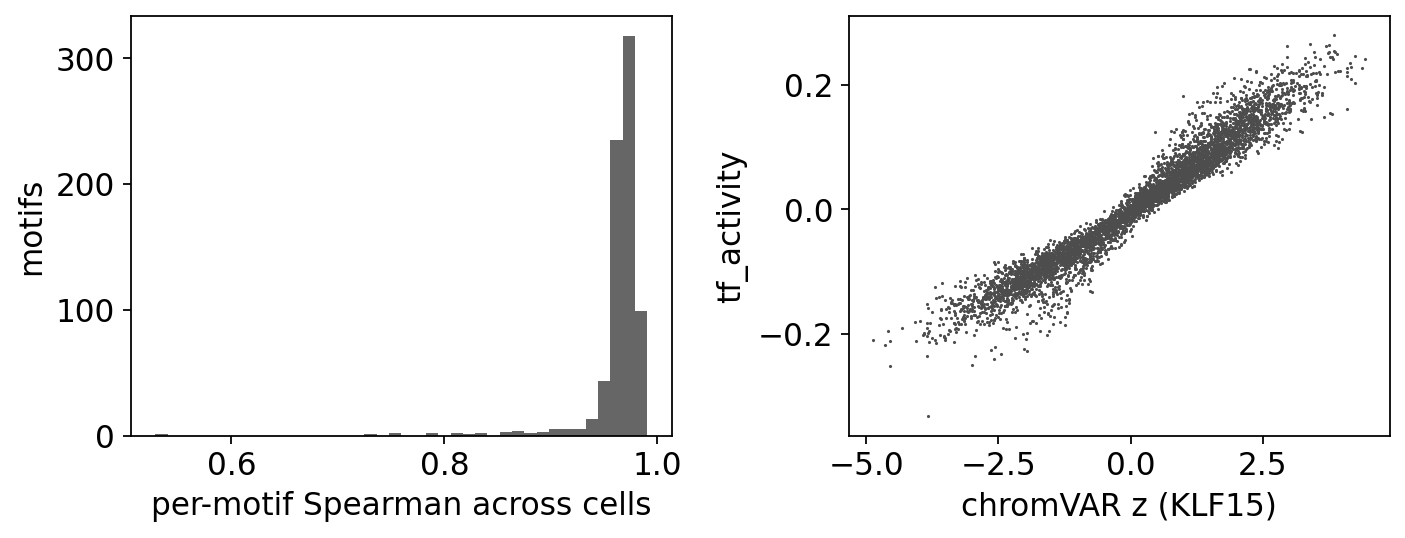

CPU times: user 5min 34s, sys: 7.25 s, total: 5min 42s
Wall time: 42.3 s


In [8]:
%%time
t0 = time.perf_counter()
epi.tl.add_background_peaks(adata, n_iterations=25, genome_fasta=str(epi.utils.genome.hg38.fasta), seed=1)
epi.tl.compute_deviations(adata)
t_cv = time.perf_counter() - t0
Zcv = adata.obsm['motif_deviations']
order = pd.Index(np.asarray(adata.uns['motif_deviations_names'])).get_indexer(names)
Zcv = Zcv[:, order]
rho = np.array([stats.spearmanr(A[:, j], Zcv[:, j]).statistic for j in range(A.shape[1])])
print(f'runtime: tf_activity {t_tfa:.1f} s | add_background_peaks + compute_deviations {t_cv:.1f} s')
print('per-motif Spearman(tf_activity, chromVAR z): median %.2f, IQR %.2f-%.2f'
      % (np.nanmedian(rho), *np.nanpercentile(rho, [25, 75])))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].hist(rho[np.isfinite(rho)], bins=40, color='0.4')
axes[0].set_xlabel('per-motif Spearman across cells'); axes[0].set_ylabel('motifs')
j = name_to_idx[top[0]]
axes[1].scatter(Zcv[:, j], A[:, j], s=2, c='0.3', linewidths=0)
axes[1].set_xlabel(f'chromVAR z ({tf_name(top[0])})'); axes[1].set_ylabel('tf_activity')
plt.tight_layout(); display(fig); plt.close(fig)

The two scores agree closely: the per-motif Spearman correlation across cells
has a median of 0.97. On this small panel (5k cells, 50k tiles, 4 threads)
`tf_activity` is slightly slower than chromVAR (see the printed times), and
adaptive shrinkage takes about half of its time. On 25k and 100k cells it was
faster (139 vs 343 s and 527 vs 574 s at 8 threads). It also needs much less
memory, because it never densifies the count matrix.

## Part 6 · How the default was chosen and how it performs

The configuration was tuned only on a CRISPR-KO Perturb-multiome screen
(GSE274113, 7 knocked-out TFs). It was then frozen and evaluated once on five
independent CRISPR screens that were not used during tuning: Spear-ATAC
K562, GM12878 and MCF7, and Perturb-ATAC GM12878 and keratinocytes (84
targeted TFs). The ground truth is that the targeted TF's own motif loses
activity in perturbed cells compared with non-targeting cells of the same
replicate.

The scores below are the means over the five held-out datasets:

| method | own-motif rank score | own-motif cell AUROC | non-targeting control rank (0.5 = calibrated) |
|---|---|---|---|
| `tf_activity` | 0.596 | 0.534 | 0.405 |
| chromVAR (R) | 0.617 | 0.537 | 0.479 |
| pychromVAR | 0.625 | 0.536 | 0.457 |
| `compute_deviations` | 0.626 | 0.538 | 0.468 |
| motif-mean baseline | 0.569 | 0.529 | 0.477 |

On these data `tf_activity` **ties** the chromVAR-type tools: every paired
bootstrap CI of the difference contains 0, and it is numerically lower on rank
score. Its calibration on non-targeting controls is worse.

Within single datasets the picture is mixed. In K562 its per-cell AUROC is
significantly higher than every other tool's; for GATA1 knockdown it is 0.95,
against 0.81 for the chromVAR-type tools. In Perturb-ATAC GM12878 its rank
score is significantly lower.

On the tuning screen it was higher than chromVAR (rank score 0.81 vs 0.76,
AUROC 0.63 vs 0.59). In a post-hoc check after the frozen evaluation, dropping
the peak-sensitivity step gave a higher held-out rank score (0.640). That
variant is not the default, because choosing it would mean choosing on the
held-out data.

It is the default because it matches chromVAR's accuracy with about a ninth
of the memory at 100k cells, is not slower, and has no sampled background.
Use `compute_deviations` when the scores must match chromVAR or ArchR.

## References

* Schep AN *et al.* chromVAR. *Nat Methods* 14, 975–978 (2017).
* Efron B. *Large-Scale Inference*. CUP (2010); Efron B, Morris C. *JASA* 68, 117–130 (1973).
* Stephens M. False discovery rates: a new deal. *Biostatistics* 18, 275–294 (2017).
* McCullagh P, Nelder JA. *Generalized Linear Models*, 2nd ed. (1989).
* Varadhan R, Roland C. SQUAREM. *Scand J Stat* 35, 335–353 (2008).
* Pierce SE *et al.* Spear-ATAC. *Nat Commun* 12, 2969 (2021); Rubin AJ *et al.* Perturb-ATAC. *Cell* 176, 361–376 (2019).